# Sloinnte: Predicting Surname Equivalence Between Irish and English Forms
**Milestone 2: Data and Baseline Checkpoint**

**Research question:** Can machine-learning models predict whether two surname forms belong to the same surname cluster in the Gaois Database of Irish-Language Surnames?

Performance is measured against the constructed Gaois cluster-based labels.

In [1]:
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
tree = ET.parse("../data/minimal.xml")
root = tree.getroot()

rows = []
for cluster_id, cluster in enumerate(root.findall("cluster")):
    title = cluster.findtext("title")
    for section in cluster:
        # section tags look like "surnames-irish-main"
        if not section.tag.startswith("surnames-"):
            continue
        _, language, status = section.tag.split("-")
        for surname in section:
            for form in surname.findall("form"):
                rows.append({
                    "cluster_id": cluster_id,
                    "title": title,
                    "form": (form.text or "").strip(),
                    "language": language,   # irish / english
                    "status": status,       # main / historical / alternative
                })

df = pd.DataFrame(rows)
df.head(10)

,cluster_id,title,form,language,status
0,0,Murchadh,Ó Murchú,irish,main
1,0,Murchadh,Mac Murchú,irish,main
2,0,Murchadh,Mac Murchaidh,irish,main
3,0,Murchadh,Mac Murchadha,irish,historical
4,0,Murchadh,Murphy,english,main
5,1,Ceallach,Ó Ceallaigh,irish,main
6,1,Ceallach,Mac Ceallaigh,irish,main
7,1,Ceallach,Kelly,english,main
8,1,Ceallach,O'Kelly,english,main
9,2,Brian,Ó Briain,irish,main


In [3]:
print("Clusters:", df["cluster_id"].nunique())   
print(df.shape)
print(df["language"].value_counts())
print(df["status"].value_counts())

Clusters: 1049
(3171, 5)
language
english    1739
irish      1432
Name: count, dtype: int64
status
main           2646
alternative     331
historical      194
Name: count, dtype: int64


3,171 forms in 1,049 clusters (1,432 Irish, 1,739 English); 2,646 main, 331 alternative, 194 historical.

In [4]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print("Empty forms:", (df["form"] == "").sum())

(3171, 5)
cluster_id    int64
title           str
form            str
language        str
status          str
dtype: object
cluster_id    0
title         0
form          0
language      0
status        0
dtype: int64
Empty forms: 7


The dataset has 3,171 forms across 5 columns, all stored as text apart from `cluster_id`. There are no missing values, but 7 forms are empty strings; these are removed during preprocessing.

In [5]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate form within same cluster:", df.duplicated(["cluster_id", "form"]).sum())

clusters_per_form = df.groupby("form")["cluster_id"].nunique()
multi = clusters_per_form[clusters_per_form > 1]
print("Forms in more than one cluster:", len(multi))   
multi.sort_values(ascending=False).head(10)

Exact duplicate rows: 0
Duplicate form within same cluster: 0
Forms in more than one cluster: 131


form
          7
Bird      4
Byron     3
Rea       3
Forde     3
Gahan     3
Green     3
Conroy    3
Mee       3
King      3
Name: cluster_id, dtype: int64

There are no exact duplicate rows. 130 non-empty forms appear in more than one cluster; the extra count of 131 comes from the empty string. To avoid leakage, clusters that share a form are grouped together before splitting.

count    1049.000000
mean        3.022879
std         1.268922
min         2.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        12.000000
dtype: float64


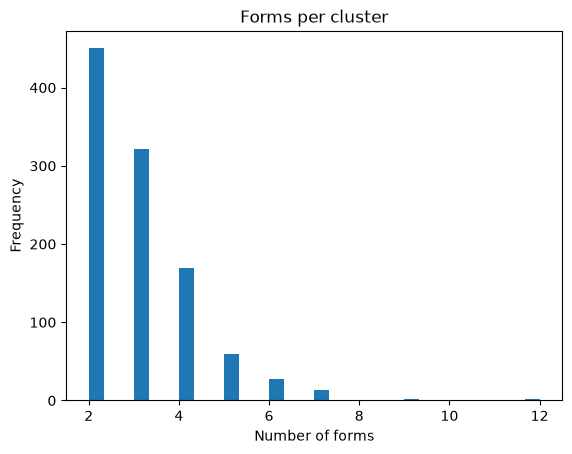

In [6]:
cluster_sizes = df.groupby("cluster_id").size()
print(cluster_sizes.describe())
cluster_sizes.plot(kind="hist", bins=30, title="Forms per cluster")
plt.xlabel("Number of forms"); plt.show()

Clusters contain 2–12 forms (median 3), so most clusters are small and produce only a few positive pairs.

count    3171.000000
mean        8.461053
std         3.121915
min         0.000000
25%         6.000000
50%         8.000000
75%        10.000000
max        23.000000
Name: length, dtype: float64
     form language
2788         irish
2360       english
186        english
2877         irish
2648         irish
                         form language
2790    Mac Giolla Gheimhridh    irish
2171    Mac an Bhreithiúnaigh    irish
1830    Mac Giolla Luaighrinn    irish
2636   Mac Giolla Chomhghaill    irish
2172  Mac an Bhreitheamhnaigh    irish


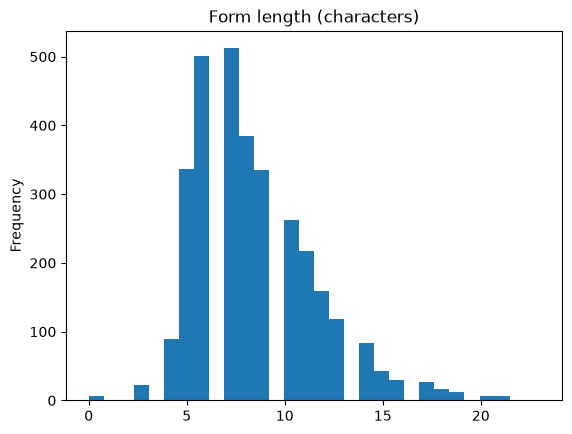

In [7]:
df["length"] = df["form"].str.len()
print(df["length"].describe())
print(df.sort_values("length").head(5)[["form", "language"]])
print(df.sort_values("length").tail(5)[["form", "language"]])
df["length"].plot(kind="hist", bins=30, title="Form length (characters)")
plt.show()

Form lengths range from 1 to 23 characters. The longest forms are relevant multi-word Irish surnames so they are kept rather than treated as outliers.

In [8]:
print(df[df["form"] == ""][["cluster_id", "title", "language", "status"]])

df = df[df["form"] != ""].reset_index(drop=True)
print("After removing empty forms:", df.shape)

# clusters that now have fewer than 2 forms can't produce positive pairs
sizes = df.groupby("cluster_id").size()
print("Clusters with <2 forms:", (sizes < 2).sum())

      cluster_id        title language       status
186           46           Sé  english         main
844          227       Giobún  english         main
2360         746         Ceat  english         main
2537         813        Beirn  english         main
2648         856  Coibheanach    irish   historical
2788         914      Bhailís    irish  alternative
2877         948     Comhghán    irish         main
After removing empty forms: (3164, 6)
Clusters with <2 forms: 0


7 empty forms were found across 7 different clusters (both languages and all statuses), so they appear to be gaps in the source data. They were removed, leaving 3,164 forms. Every cluster still has at least 2 forms, so all 1,049 clusters remain usable.

In [9]:
import networkx as nx

G = nx.Graph()
for cid, form in df[["cluster_id", "form"]].itertuples(index=False):
    G.add_edge(("cluster", cid), ("form", form))

cluster_to_group = {}
for gid, component in enumerate(nx.connected_components(G)):
    for kind, value in component:
        if kind == "cluster":
            cluster_to_group[value] = gid

df["group_id"] = df["cluster_id"].map(cluster_to_group)

group_sizes = df.groupby("group_id")["cluster_id"].nunique()
print("Groups:", df["group_id"].nunique())
print("Largest group (clusters):", group_sizes.max())

Groups: 938
Largest group (clusters): 5


Clusters that share at least one form were merged into groups using connected components. The 1,049 clusters form 938 groups; the largest contains 5 clusters. These groups are used for all splitting, so a shared form can never appear on both sides of a split.

In [10]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df["group_id"]))
train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

print("Train forms:", len(train_df), "| Test forms:", len(test_df))
print("Train clusters:", train_df["cluster_id"].nunique(), "| Test clusters:", test_df["cluster_id"].nunique())
print("Forms in both train and test:", len(set(train_df["form"]) & set(test_df["form"])))  # must be 0

Train forms: 2531 | Test forms: 633
Train clusters: 840 | Test clusters: 209
Forms in both train and test: 0


A grouped 80/20 split (`GroupShuffleSplit`, `random_state=42`) gives 2,531 training forms (840 clusters) and 633 test forms (209 clusters). No form appears in both sets. The test set is held out and is not used until final evaluation.

In [11]:
from itertools import combinations

def make_pairs(split_df, neg_ratio=1, seed=42):
    """Build positive and negative pairs using ONLY the forms in split_df."""
    rng = np.random.default_rng(seed)
    form_clusters = split_df.groupby("form")["cluster_id"].apply(set).to_dict()

    # Positives: two forms in the same cluster, at least one Irish
    pos = {}
    for cid, g in split_df.groupby("cluster_id"):
        items = list(g[["form", "language"]].itertuples(index=False, name=None))
        for (f1, l1), (f2, l2) in combinations(items, 2):
            if f1 == f2 or "irish" not in (l1, l2):
                continue
            pos[frozenset([f1, f2])] = "ga-ga" if l1 == l2 else "ga-en"

    # Negatives: forms from different clusters, same pair type as each positive
    irish = split_df.loc[split_df["language"] == "irish", "form"].unique()
    english = split_df.loc[split_df["language"] == "english", "form"].unique()
    neg = {}
    for ptype in pos.values():
        made = 0
        while made < neg_ratio:
            a = rng.choice(irish)
            b = rng.choice(irish if ptype == "ga-ga" else english)
            key = frozenset([a, b])
            if a == b or key in pos or key in neg or form_clusters[a] & form_clusters[b]:
                continue
            neg[key] = ptype
            made += 1

    rows = [(*sorted(k), t, 1) for k, t in pos.items()] + \
           [(*sorted(k), t, 0) for k, t in neg.items()]
    return pd.DataFrame(rows, columns=["form_a", "form_b", "pair_type", "is_match"])

In [12]:
import re, unicodedata
from rapidfuzz.distance import Levenshtein

IRISH_PREFIXES = {"o", "ua", "ui", "ni", "mac", "mag", "mhic", "nic", "de", "bean", "an"}

def normalise(s):
    s = unicodedata.normalize("NFD", s.lower().strip())
    return "".join(c for c in s if unicodedata.category(c) != "Mn")  # removes fadas

def strip_prefix(s):
    parts = s.split()
    while len(parts) > 1 and parts[0] in IRISH_PREFIXES:
        parts = parts[1:]
    s = " ".join(parts)
    return re.sub(r"^(o'|mc)", "", s)

def add_features(pairs):
    pairs = pairs.copy()
    a = pairs["form_a"].map(normalise)
    b = pairs["form_b"].map(normalise)
    la, lb = a.str.len(), b.str.len()
    pairs["edit_dist"] = [Levenshtein.normalized_distance(x, y) for x, y in zip(a, b)]
    pairs["len_diff"] = (la - lb).abs()
    pairs["len_ratio"] = np.minimum(la, lb) / np.maximum(la, lb)
    pairs["shared_chars"] = [len(set(x) & set(y)) / len(set(x) | set(y)) for x, y in zip(a, b)]
    pairs["same_first_letter"] = [int(strip_prefix(x)[:1] == strip_prefix(y)[:1]) for x, y in zip(a, b)]
    pairs["cross_lang"] = (pairs["pair_type"] == "ga-en").astype(int)
    return pairs

FEATURES = ["edit_dist", "len_diff", "len_ratio", "shared_chars", "same_first_letter", "cross_lang"]

In [13]:
train_pairs = add_features(make_pairs(train_df, seed=0))
test_pairs = add_features(make_pairs(test_df, seed=1))

print("Train pairs:", len(train_pairs), "| Test pairs:", len(test_pairs))
print(train_pairs["is_match"].value_counts())
print(train_pairs.groupby(["pair_type", "is_match"]).size())
train_pairs.head()

Train pairs: 4784 | Test pairs: 1136
is_match
1    2392
0    2392
Name: count, dtype: int64
pair_type  is_match
ga-en      0           2013
           1           2013
ga-ga      0            379
           1            379
dtype: int64


,form_a,form_b,pair_type,is_match,edit_dist,len_diff,len_ratio,shared_chars,same_first_letter,cross_lang
0,Mac Murchú,Ó Murchú,ga-ga,1,0.300000,2,0.800000,0.750000,1,0
1,Mac Murchaidh,Ó Murchú,ga-ga,1,0.538462,5,0.615385,0.600000,1,0
2,Mac Murchadha,Ó Murchú,ga-ga,1,0.538462,5,0.615385,0.666667,1,0
3,Murphy,Ó Murchú,ga-en,1,0.500000,2,0.750000,0.444444,1,1
4,Mac Murchaidh,Mac Murchú,ga-ga,1,0.307692,3,0.769231,0.777778,1,0


Pairs are built separately within the training and test forms, so no test form appears in any training pair. There are 2,960 positive pairs in total; 2,392 are in training. Positives are Irish–Irish or Irish–English pairs from the same cluster. Negatives are sampled at a 1:1 ratio from forms in different clusters, matching the pair type of each positive, so the target is balanced by construction. Negatives are assumed, not verified: forms in different clusters are not confirmed to be different surnames.

Dummy CV F1: 0.482 ± 0.003
Best edit-distance threshold: 0.75 | CV F1: 0.789


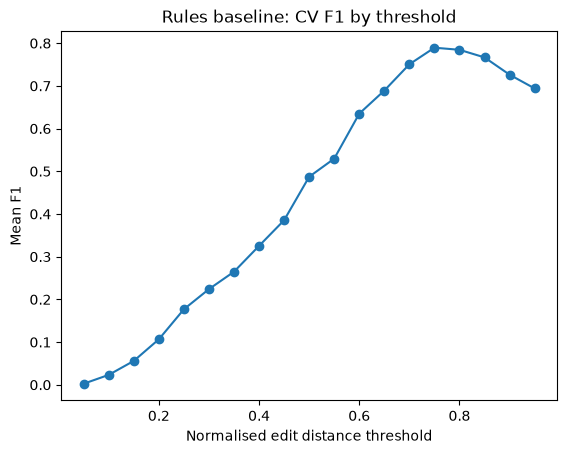

In [14]:
from sklearn.model_selection import GroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

thresholds = np.round(np.arange(0.05, 1.0, 0.05), 2)
gkf = GroupKFold(n_splits=5)
rule_scores = {t: [] for t in thresholds}
dummy_scores = []

for fold, (tr_i, va_i) in enumerate(gkf.split(train_df, groups=train_df["group_id"])):
    fold_tr = add_features(make_pairs(train_df.iloc[tr_i], seed=fold))
    fold_va = add_features(make_pairs(train_df.iloc[va_i], seed=fold + 100))

    for t in thresholds:
        pred = (fold_va["edit_dist"] <= t).astype(int)
        rule_scores[t].append(f1_score(fold_va["is_match"], pred))

    dummy = DummyClassifier(strategy="stratified", random_state=42)
    dummy.fit(fold_tr[FEATURES], fold_tr["is_match"])
    dummy_scores.append(f1_score(fold_va["is_match"], dummy.predict(fold_va[FEATURES])))

cv_rule = pd.Series({t: np.mean(s) for t, s in rule_scores.items()})
best_t = cv_rule.idxmax()
print("Dummy CV F1: %.3f ± %.3f" % (np.mean(dummy_scores), np.std(dummy_scores)))
print("Best edit-distance threshold:", best_t, "| CV F1: %.3f" % cv_rule.max())
cv_rule.plot(marker="o", title="Rules baseline: CV F1 by threshold")
plt.xlabel("Normalised edit distance threshold"); plt.ylabel("Mean F1"); plt.show()

The test F1 (0.770) is close to the cross-validation F1 (0.789), suggesting the threshold generalises to unseen clusters.

,F1,Precision,Recall,ROC-AUC
Dummy (stratified),0.472,0.473,0.472,0.473
Rules (edit dist ≤ 0.75),0.770,0.781,0.759,0.863


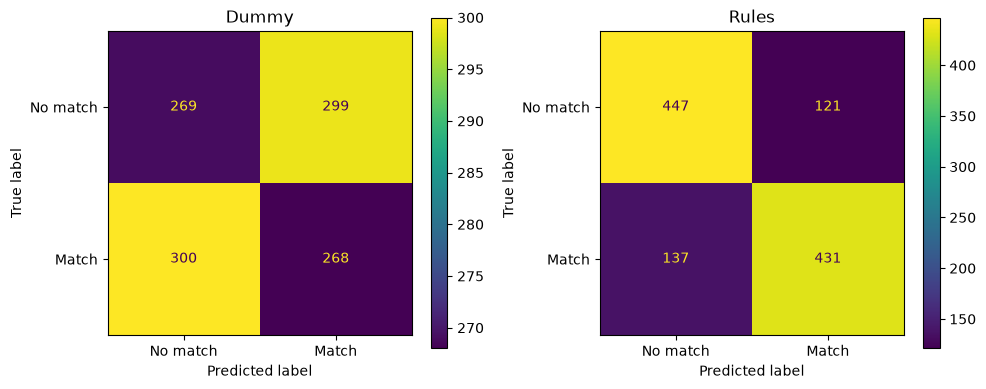

In [15]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay

y_test = test_pairs["is_match"]

dummy = DummyClassifier(strategy="stratified", random_state=42).fit(train_pairs[FEATURES], train_pairs["is_match"])
dummy_pred = dummy.predict(test_pairs[FEATURES])
dummy_score = dummy.predict_proba(test_pairs[FEATURES])[:, 1]

rule_pred = (test_pairs["edit_dist"] <= best_t).astype(int)
rule_score = 1 - test_pairs["edit_dist"]   # higher = more similar

results = pd.DataFrame({
    name: {
        "F1": f1_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "ROC-AUC": roc_auc_score(y_test, s),
    }
    for name, p, s in [("Dummy (stratified)", dummy_pred, dummy_score),
                       (f"Rules (edit dist ≤ {best_t})", rule_pred, rule_score)]
}).T.round(3)
display(results)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, p) in zip(axes, [("Dummy", dummy_pred), ("Rules", rule_pred)]):
    ConfusionMatrixDisplay.from_predictions(y_test, p, ax=ax, display_labels=["No match", "Match"])
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [16]:
from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y_test, rule_pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

TN=447  FP=121  FN=137  TP=431


On the held-out test set, measured against the constructed Gaois cluster-based labels, the rules baseline reaches F1 0.770 (precision 0.781, recall 0.759, ROC-AUC 0.863), compared with 0.472 for the stratified dummy. The confusion matrix shows the errors are fairly balanced between missed matches and false matches. The high threshold (0.75) shows that many true matches, especially Irish–English pairs such as *Murphy* / *Ó Murchú*, are not close in spelling. This is the main weakness the learned models in Milestone 3 will try to address.